# UTS Pembelajaran Mesin - Decision Tree & Naive Bayes
Dataset: Heart Disease (prediksi `HeartDisease`)  
202531081_M. Fasha Bintang Pratama

## Import library


In [1]:
# 202531081_M. Fasha Bintang Pratama

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## Membaca dataset


In [2]:
# 202531081_M. Fasha Bintang Pratama
df = pd.read_csv("01_heart_disease.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Melihat informasi dataset (EDA)


In [3]:
# 202531081_M. Fasha Bintang Pratama
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


## Cek data kosong, duplikat, dan nilai 0 yang janggal


In [4]:
# 202531081_M. Fasha Bintang Pratama
print("Data kosong:")
print(df.isnull().sum())
print("Data duplikat:", df.duplicated().sum())
print("Jumlah Cholesterol = 0 :", (df["Cholesterol"] == 0).sum())
print("Jumlah RestingBP   = 0 :", (df["RestingBP"] == 0).sum())

Data kosong:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Data duplikat: 0
Jumlah Cholesterol = 0 : 172
Jumlah RestingBP   = 0 : 1


## Melihat sebaran kelas HeartDisease


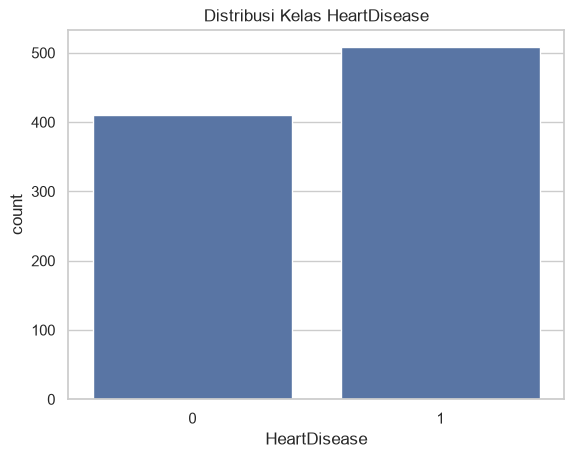

HeartDisease
1    508
0    410
Name: count, dtype: int64


In [5]:
# 202531081_M. Fasha Bintang Pratama
sns.countplot(x="HeartDisease", data=df)
plt.title("Distribusi Kelas HeartDisease")
plt.show()
print(df["HeartDisease"].value_counts())

## Memisahkan fitur numerik dan kategorikal


In [6]:
# 202531081_M. Fasha Bintang Pratama
numerical_features = [f for f in df.columns if df[f].dtypes != "str"]
categorical_features = [f for f in df.columns if df[f].dtypes == "str"]

print("jumlah fitur numerik =", len(numerical_features))
print("daftar fitur numerik =", numerical_features)
print("jumlah fitur kategorikal =", len(categorical_features))
print("daftar fitur kategorikal =", categorical_features)

for i in categorical_features:
    print(i, ":", df[i].unique())

jumlah fitur numerik = 7
daftar fitur numerik = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']
jumlah fitur kategorikal = 5
daftar fitur kategorikal = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Sex : <StringArray>
['M', 'F']
Length: 2, dtype: str
ChestPainType : <StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
RestingECG : <StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
ExerciseAngina : <StringArray>
['N', 'Y']
Length: 2, dtype: str
ST_Slope : <StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


## Grafik fitur kategorikal terhadap HeartDisease


Text(0.5, 1.0, 'ST_Slope')

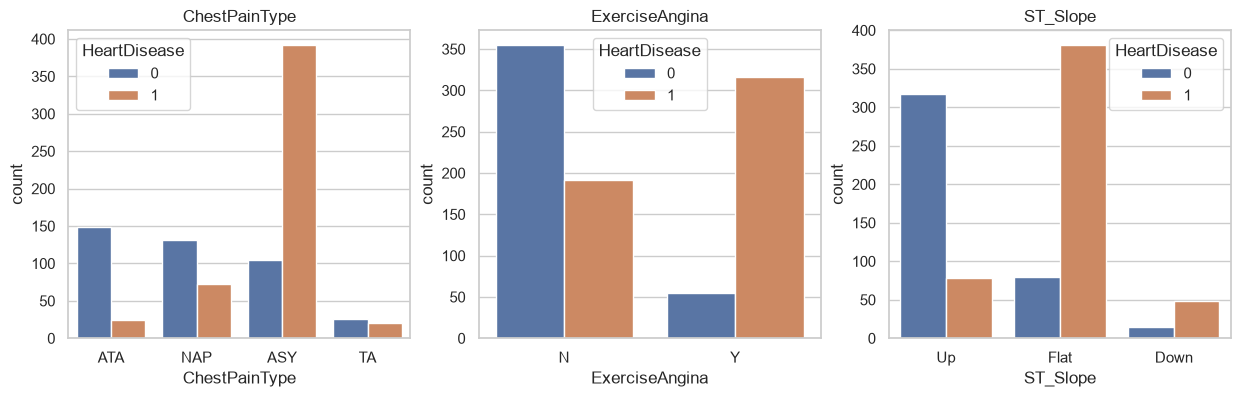

In [7]:
# 202531081_M. Fasha Bintang Pratama
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.countplot(x="ChestPainType", hue="HeartDisease", data=df)
plt.title("ChestPainType")

plt.subplot(1, 3, 2)
sns.countplot(x="ExerciseAngina", hue="HeartDisease", data=df)
plt.title("ExerciseAngina")

plt.subplot(1, 3, 3)
sns.countplot(x="ST_Slope", hue="HeartDisease", data=df)
plt.title("ST_Slope")



## Boxplot fitur numerik terhadap HeartDisease


Text(0.5, 1.0, 'Cholesterol')

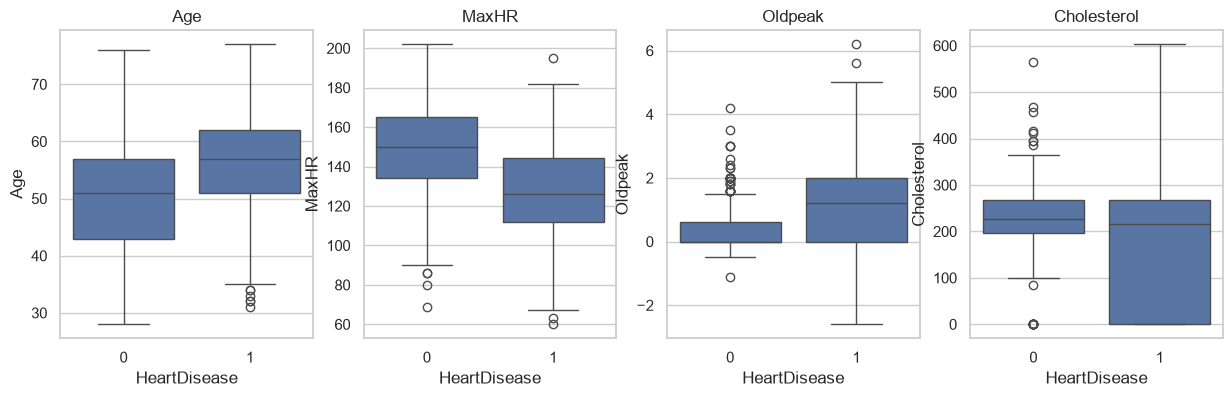

In [8]:
# 202531081_M. Fasha Bintang Pratama
plt.figure(figsize=(15, 4))

plt.subplot(1, 4, 1)
sns.boxplot(x="HeartDisease", y="Age", data=df)
plt.title("Age")

plt.subplot(1, 4, 2)
sns.boxplot(x="HeartDisease", y="MaxHR", data=df)
plt.title("MaxHR")

plt.subplot(1, 4, 3)
sns.boxplot(x="HeartDisease", y="Oldpeak", data=df)
plt.title("Oldpeak")

plt.subplot(1, 4, 4)
sns.boxplot(x="HeartDisease", y="Cholesterol", data=df)
plt.title("Cholesterol")


## Preprocessing: mengganti nilai 0 dengan median


In [9]:
# 202531081_M. Fasha Bintang Pratama
for kolom in ["Cholesterol", "RestingBP"]:
    median = df.loc[df[kolom] != 0, kolom].median()
    df[kolom] = df[kolom].replace(0, median)
    print(kolom, "-> nilai 0 diganti median", median)

print("Cholesterol minimum sekarang:", df["Cholesterol"].min())
print("RestingBP minimum sekarang  :", df["RestingBP"].min())

Cholesterol -> nilai 0 diganti median 237.0
RestingBP -> nilai 0 diganti median 130.0
Cholesterol minimum sekarang: 85
RestingBP minimum sekarang  : 80


## Preprocessing: mengubah data huruf menjadi angka


In [10]:
# 202531081_M. Fasha Bintang Pratama
from sklearn.preprocessing import LabelEncoder

for feature in categorical_features:
    le = LabelEncoder()
    df[feature] = le.fit_transform(df[feature])
    print(feature, ":", {label: i for i, label in enumerate(le.classes_)})

df.head()

Sex : {'F': 0, 'M': 1}
ChestPainType : {'ASY': 0, 'ATA': 1, 'NAP': 2, 'TA': 3}
RestingECG : {'LVH': 0, 'Normal': 1, 'ST': 2}
ExerciseAngina : {'N': 0, 'Y': 1}
ST_Slope : {'Down': 0, 'Flat': 1, 'Up': 2}


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


## Heatmap korelasi


ST_Slope         -0.558771
MaxHR            -0.400421
ChestPainType    -0.386828
RestingECG        0.057384
Cholesterol       0.076114
RestingBP         0.117798
FastingBS         0.267291
Age               0.282039
Sex               0.305445
Oldpeak           0.403951
ExerciseAngina    0.494282
Name: HeartDisease, dtype: float64


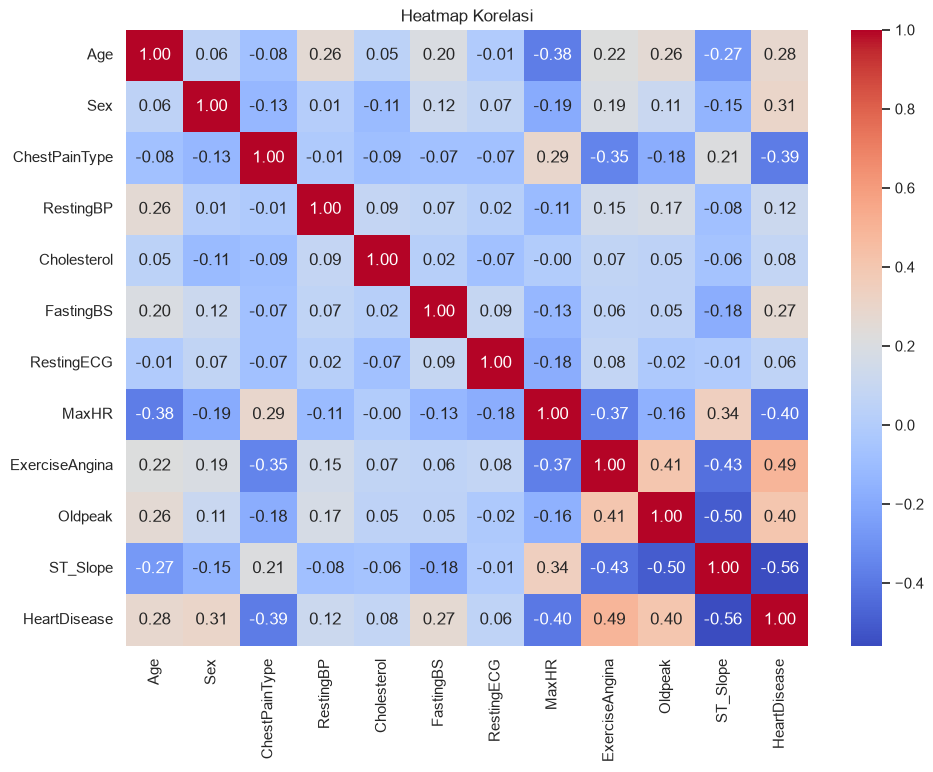

In [11]:
# 202531081_M. Fasha Bintang Pratama
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Heatmap Korelasi")
print(df.corr()["HeartDisease"].drop("HeartDisease").sort_values())

## Memisahkan fitur (x) dan target (y)


In [12]:
# 202531081_M. Fasha Bintang Pratama
x = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]
print("Bentuk x:", x.shape)
print("Bentuk y:", y.shape)

Bentuk x: (918, 11)
Bentuk y: (918,)


## Membagi data latih dan data uji


In [13]:
# 202531081_M. Fasha Bintang Pratama
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)
print("x_train:", x_train.shape)
print("x_test :", x_test.shape)

x_train: (688, 11)
x_test : (230, 11)


## Decision Tree - model pertama (pengaturan bawaan)


In [14]:
# 202531081_M. Fasha Bintang Pratama
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt1 = DecisionTreeClassifier(random_state=0)
dt1.fit(x_train, y_train)

print("Kedalaman pohon:", dt1.get_depth())
print("Akurasi data latih:", accuracy_score(y_train, dt1.predict(x_train)))
print("Akurasi data uji  :", accuracy_score(y_test, dt1.predict(x_test)))

Kedalaman pohon: 13
Akurasi data latih: 1.0
Akurasi data uji  : 0.7695652173913043


## Decision Tree - mencoba beberapa max_depth


max_depth terbaik: 6 | akurasi: 0.8391304347826087


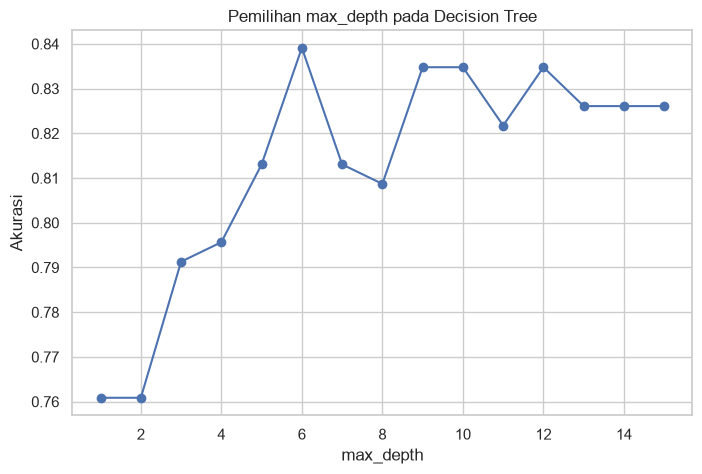

In [15]:
# 202531081_M. Fasha Bintang Pratama
depths = range(1, 16)
akurasi_dt = []

for d in depths:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)
    model.fit(x_train, y_train)
    akurasi_dt.append(accuracy_score(y_test, model.predict(x_test)))

plt.figure(figsize=(8, 5))
plt.plot(depths, akurasi_dt, marker="o")
plt.xlabel("max_depth")
plt.ylabel("Akurasi")
plt.title("Pemilihan max_depth pada Decision Tree")

best_depth = depths[akurasi_dt.index(max(akurasi_dt))]
print("max_depth terbaik:", best_depth, "| akurasi:", max(akurasi_dt))

## Decision Tree - model akhir dan akurasi


In [16]:
# 202531081_M. Fasha Bintang Pratama
from sklearn.metrics import classification_report

dt = DecisionTreeClassifier(criterion="entropy", max_depth=best_depth, random_state=0)
dt.fit(x_train, y_train)
pred_dt = dt.predict(x_test)

akurasi_dt_final = accuracy_score(y_test, pred_dt)
print("Kedalaman pohon:", dt.get_depth())
print("Akurasi Decision Tree:", akurasi_dt_final)
print(classification_report(y_test, pred_dt))

Kedalaman pohon: 6
Akurasi Decision Tree: 0.8391304347826087
              precision    recall  f1-score   support

           0       0.80      0.79      0.80        92
           1       0.86      0.87      0.87       138

    accuracy                           0.84       230
   macro avg       0.83      0.83      0.83       230
weighted avg       0.84      0.84      0.84       230



## Decision Tree - gambar pohon dan fitur penting


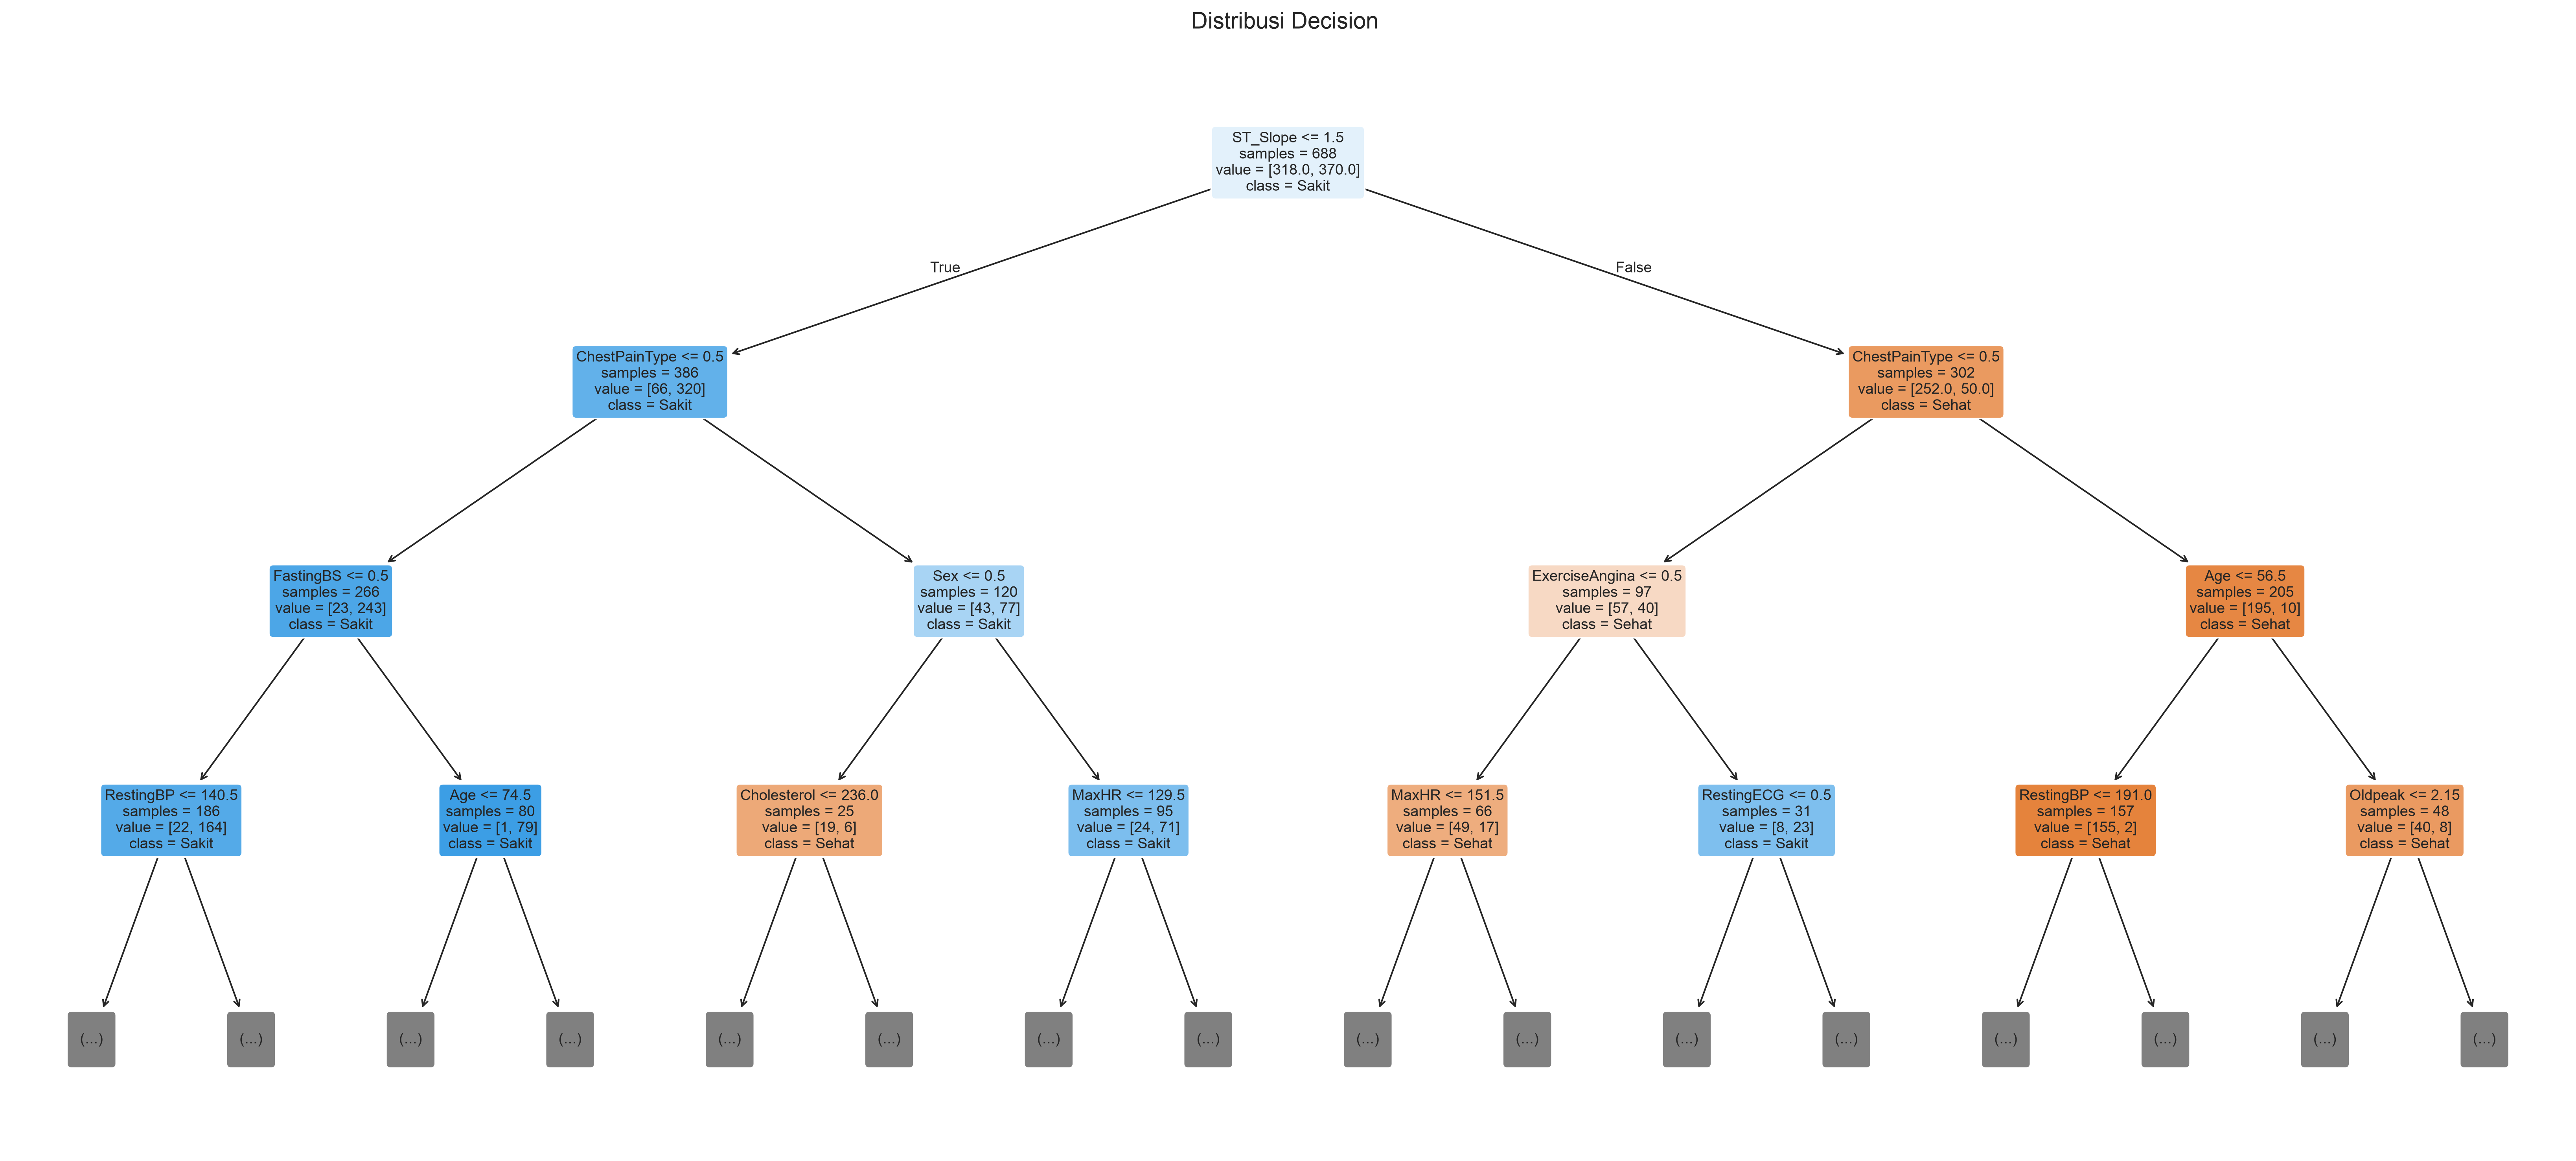

ST_Slope          0.476302
ChestPainType     0.152589
Cholesterol       0.078124
RestingBP         0.049610
Age               0.044036
ExerciseAngina    0.040927
dtype: float64


In [17]:
# 202531081_M. Fasha Bintang Pratama
from sklearn import tree
plt.figure(figsize=(22, 10), dpi=300)
tree.plot_tree(
    dt, 
    feature_names=x.columns, 
    class_names=["Sehat", "Sakit"], 
    filled=True, 
    fontsize=9,
    max_depth=3,        
    impurity=False,     
    rounded=True,       
    precision=2         
)

plt.title("Distribusi Decision ", fontsize=14, pad=15)
plt.tight_layout()
plt.show()
penting = pd.Series(dt.feature_importances_, index=x.columns).sort_values(ascending=False)
print(penting.head(6))

## Naive Bayes - membuat model dan prediksi


In [18]:
# 202531081_M. Fasha Bintang Pratama
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(x_train, y_train)

y_pred_train = nb.predict(x_train)
y_pred_test = nb.predict(x_test)

print("Akurasi data latih:", accuracy_score(y_train, y_pred_train))
print("Akurasi data uji  :", accuracy_score(y_test, y_pred_test))

Akurasi data latih: 0.8517441860465116
Akurasi data uji  : 0.8260869565217391


## Naive Bayes - evaluasi dengan confusion matrix


evaluasi data uji:
[[ 73  19]
 [ 21 117]]
              precision    recall  f1-score   support

       Sehat       0.78      0.79      0.78        92
       Sakit       0.86      0.85      0.85       138

    accuracy                           0.83       230
   macro avg       0.82      0.82      0.82       230
weighted avg       0.83      0.83      0.83       230



Text(569.4121636284721, 0.5, 'True Label')

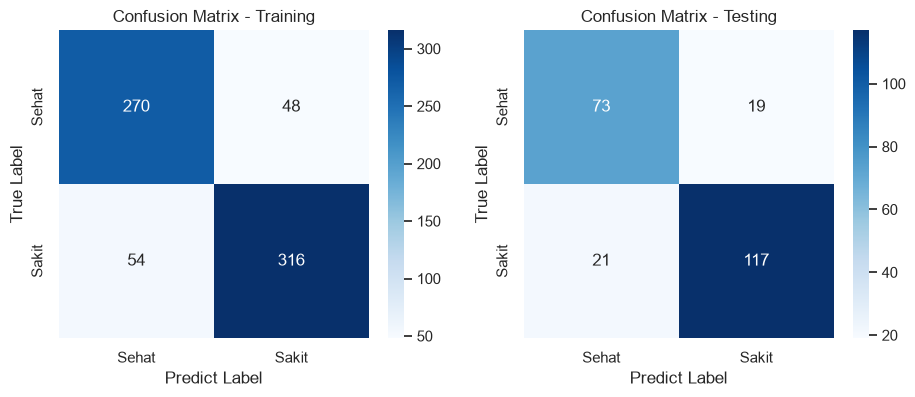

In [19]:
# 202531081_M. Fasha Bintang Pratama
from sklearn.metrics import confusion_matrix

cm_train = confusion_matrix(y_train, y_pred_train)
cm_test = confusion_matrix(y_test, y_pred_test)

print("evaluasi data uji:")
print(cm_test)
print(classification_report(y_test, y_pred_test, target_names=["Sehat", "Sakit"]))

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
sns.heatmap(cm_train, annot=True, fmt="d", cmap="Blues", xticklabels=["Sehat", "Sakit"], yticklabels=["Sehat", "Sakit"])
plt.title("Confusion Matrix - Training")
plt.xlabel("Predict Label")
plt.ylabel("True Label")

plt.subplot(1, 2, 2)
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", xticklabels=["Sehat", "Sakit"], yticklabels=["Sehat", "Sakit"])
plt.title("Confusion Matrix - Testing")
plt.xlabel("Predict Label")
plt.ylabel("True Label")



## Decision Tree - confusion matrix


[[ 73  19]
 [ 18 120]]


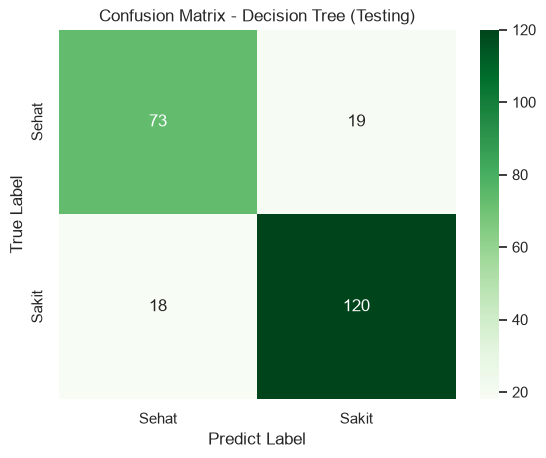

In [20]:
# 202531081_M. Fasha Bintang Pratama
cm_dt = confusion_matrix(y_test, pred_dt)
print(cm_dt)

sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens", xticklabels=["Sehat", "Sakit"], yticklabels=["Sehat", "Sakit"])
plt.title("Confusion Matrix - Decision Tree (Testing)")
plt.xlabel("Predict Label")
plt.ylabel("True Label")
plt.show()

## Mencoba memprediksi satu pasien


In [21]:
# 202531081_M. Fasha Bintang Pratama
pasien = x_test.iloc[[0]]
print(pasien)
print("Kondisi sebenarnya    :", y_test.iloc[0])
print("Prediksi Decision Tree:", dt.predict(pasien)[0])
print("Prediksi Naive Bayes  :", nb.predict(pasien)[0])

     Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  RestingECG  \
306   55    1              0        115          237          1           1   

     MaxHR  ExerciseAngina  Oldpeak  ST_Slope  
306    155               0      0.1         1  
Kondisi sebenarnya    : 1
Prediksi Decision Tree: 1
Prediksi Naive Bayes  : 1


## Perbandingan Decision Tree dan Naive Bayes


           Model   Akurasi
0  Decision Tree  0.839130
1    Naive Bayes  0.826087


Text(0.5, 1.0, 'Perbandingan Akurasi')

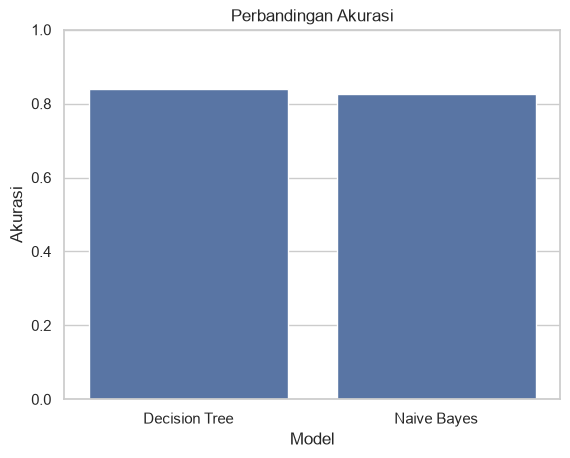

In [22]:
# 202531081_M. Fasha Bintang Pratama
akurasi_nb_final = accuracy_score(y_test, y_pred_test)

hasil = pd.DataFrame({
    "Model": ["Decision Tree", "Naive Bayes"],
    "Akurasi": [akurasi_dt_final, akurasi_nb_final]
})
print(hasil)

sns.barplot(x="Model", y="Akurasi", data=hasil)
plt.ylim(0, 1)
plt.title("Perbandingan Akurasi")
